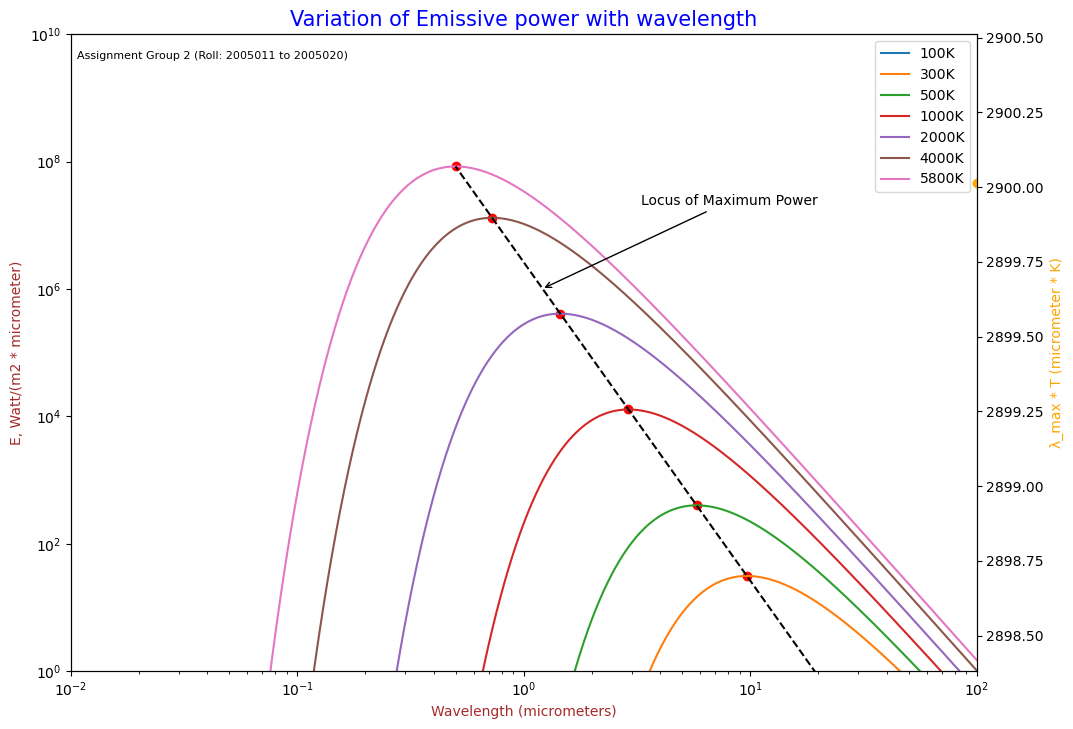

In [4]:
import matplotlib.pyplot as plt
import numpy as np

h = 6.626e-34
c = 2.9979e+8
k = 1.38e-23

def Emission(lemda, Temperature):
    C1 = 2.0 * np.pi * h * c**2 
    p = h * c / (lemda * 1e3 * 1e-9 * k * Temperature)
    E = C1 / (((lemda * 1e3 * 1e-9)**5) * (np.exp(p) - 1.0)) * 1e-6
    return E

def find_peak(wavelengths, Emission):
    max_Emission = np.max(Emission)
    max_index = np.argmax(Emission)
    max_wavelength = wavelengths[max_index]
    return max_wavelength, max_Emission

wavelengths = np.logspace(-2, 2, num=10000, endpoint=False)
temperatures = [100, 300, 500, 1000, 2000, 4000, 5800]

plt.figure(figsize=(11.69, 8.27))

peak_points = []                     
lambda_T_products = []  # to store lambda * T products

for temp in temperatures:
    emission = Emission(wavelengths, temp)  
    max_wavelength, max_Emission = find_peak(wavelengths, emission)
    
    plt.loglog(wavelengths, emission, label=f'{temp}K')
    
    plt.scatter(max_wavelength, max_Emission, color='red')
    
    lambda_T_product = max_wavelength * temp  # calculate lambda * T
    lambda_T_products.append(lambda_T_product)
    
    peak_points.append((max_wavelength, max_Emission))


peak_points = np.array(peak_points)
plt.plot(peak_points[:, 0], peak_points[:, 1], linestyle='--', color='black')

plt.xlim([1e-2, 1e2])
plt.ylim([1, 1e10])
plt.xlabel('Wavelength (micrometers)', color='brown')
plt.ylabel('E, Watt/(m2 * micrometer)', color='brown')
plt.legend()
plt.title('Variation of Emissive power with wavelength', color='blue', fontsize='15')
plt.figtext(.13, .85, "Assignment Group 2 (Roll: 2005011 to 2005020)", fontsize=8)

arrow_x = 1.2  
arrow_y = 1e6 
plt.annotate('Locus of Maximum Power', xy=(arrow_x, arrow_y), xytext=(arrow_x + 2.1, arrow_y + 0.2e8),
             arrowprops=dict(facecolor='black', arrowstyle='->'),
             fontsize=10,
             xycoords='data', textcoords='data')

# Plot lambda * T products against temperature on a secondary axis
ax2 = plt.gca().twinx()
ax2.plot(temperatures, lambda_T_products, color='orange', marker='o', linestyle='-')
ax2.set_ylabel('λ_max * T (micrometer * K)', color='orange')

plt.show()
